# Fase 1 — Análise Exploratória de Dados (EDA) e Pré-processamento

**Projeto:** Redes Sociais vs Produtividade — Aprendizado de Máquina via Random Forest

Objetivos deste notebook:

1. Carregar o dataset bruto e avaliar sua qualidade (tipos, nulos, duplicatas).
2. Explorar livremente o comportamento humano descrito nos dados: distribuições, correlações lineares e não lineares, e cruzamentos entre hábitos digitais, bem-estar e produtividade.
3. Definir a variável alvo e justificar a escolha entre **classificação** e **regressão**.
4. Tratar valores nulos, converter variáveis categóricas em numéricas e salvar o dataset pronto para a modelagem em `data/processed.csv`.

## 1. Configuração do ambiente

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.feature_selection import mutual_info_regression

RANDOM_STATE = 42
DATA_RAW = Path("social_media_vs_productivity.csv")
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# Paleta validada para daltonismo (ordem fixa das cores categóricas)
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
GRID = "#e4e3df"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA = CAT[0], CAT[1], CAT[2]
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
DIV = LinearSegmentedColormap.from_list("div_red_blue", ["#e34948", "#f0efec", "#2a78d6"])

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
    "axes.edgecolor": INK_2,
    "axes.labelcolor": INK,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "text.color": INK,
    "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=CAT),
})


def salvar(fig, nome):
    # Exporta a figura para a pasta figures/ (usada também nos slides)
    fig.savefig(FIG_DIR / f"{nome}.png", dpi=150, bbox_inches="tight")


pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.2f}".format)

## 2. Carregamento dos dados

In [2]:
df_raw = pd.read_csv(DATA_RAW)
print(f"Formato: {df_raw.shape[0]:,} linhas × {df_raw.shape[1]} colunas")
df_raw.head()

Formato: 30,000 linhas × 19 colunas


,age,gender,job_type,daily_social_media_time,social_platform_preference,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,uses_focus_apps,has_digital_wellbeing_enabled,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,job_satisfaction_score
0,56,Male,Unemployed,4.18,Facebook,61,6.75,8.04,7.29,4.00,5.12,0.42,8,False,False,4,11,21.93,6.34
1,46,Male,Health,3.25,Twitter,59,9.17,5.06,5.17,7.00,5.10,0.67,7,True,True,2,25,0.00,3.41
2,32,Male,Finance,NaN,Twitter,57,7.91,3.86,3.47,4.00,8.58,0.62,0,True,False,3,17,10.32,2.47
3,60,Female,Unemployed,NaN,Facebook,59,6.36,2.92,1.77,6.00,6.05,1.20,1,False,False,0,4,23.88,1.73
4,25,Male,IT,NaN,Telegram,66,6.21,8.87,NaN,7.00,5.41,1.88,1,False,True,1,30,10.65,9.69


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             30000 non-null  int64  
 1   gender                          30000 non-null  str    
 2   job_type                        30000 non-null  str    
 3   daily_social_media_time         27235 non-null  float64
 4   social_platform_preference      30000 non-null  str    
 5   number_of_notifications         30000 non-null  int64  
 6   work_hours_per_day              30000 non-null  float64
 7   perceived_productivity_score    28386 non-null  float64
 8   actual_productivity_score       27635 non-null  float64
 9   stress_level                    28096 non-null  float64
 10  sleep_hours                     27402 non-null  float64
 11  screen_time_before_sleep        27789 non-null  float64
 12  breaks_during_work              30000 non-n

In [4]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,30000.00,41.49,13.84,18.00,30.00,41.00,53.00,65.00
daily_social_media_time,27235.00,3.11,2.07,0.00,1.64,3.03,4.37,17.97
number_of_notifications,30000.00,59.96,7.72,30.00,55.00,60.00,65.00,90.00
work_hours_per_day,30000.00,6.99,2.00,0.00,5.64,6.99,8.35,12.00
perceived_productivity_score,28386.00,5.51,2.02,2.00,3.76,5.53,7.27,9.00
actual_productivity_score,27635.00,4.95,1.88,0.30,3.37,4.95,6.53,9.85
stress_level,28096.00,5.51,2.87,1.00,3.00,6.00,8.00,10.00
sleep_hours,27402.00,6.50,1.46,3.00,5.49,6.50,7.50,10.00
screen_time_before_sleep,27789.00,1.03,0.65,0.00,0.53,1.01,1.48,3.00
breaks_during_work,30000.00,4.99,3.17,0.00,2.00,5.00,8.00,10.00


### Dicionário de variáveis

| Coluna | Descrição | Tipo |
|---|---|---|
| `age` | Idade | numérica |
| `gender` | Gênero (Male, Female, Other) | categórica nominal |
| `job_type` | Área de atuação | categórica nominal |
| `daily_social_media_time` | Horas por dia em redes sociais | numérica |
| `social_platform_preference` | Rede social favorita | categórica nominal |
| `number_of_notifications` | Notificações recebidas por dia | numérica |
| `work_hours_per_day` | Horas de trabalho por dia | numérica |
| `perceived_productivity_score` | Produtividade **autoavaliada** (0–10) | numérica |
| `actual_productivity_score` | Produtividade **real/medida** (0–10) | numérica |
| `stress_level` | Nível de estresse (1–10) | numérica |
| `sleep_hours` | Horas de sono | numérica |
| `screen_time_before_sleep` | Horas de tela antes de dormir | numérica |
| `breaks_during_work` | Pausas durante o trabalho | numérica |
| `uses_focus_apps` | Usa apps de foco | booleana |
| `has_digital_wellbeing_enabled` | Tem bem-estar digital ativado | booleana |
| `coffee_consumption_per_day` | Xícaras de café por dia | numérica |
| `days_feeling_burnout_per_month` | Dias com sensação de burnout no mês | numérica |
| `weekly_offline_hours` | Horas offline por semana | numérica |
| `job_satisfaction_score` | Satisfação com o trabalho (0–10) | numérica |

## 3. Qualidade dos dados

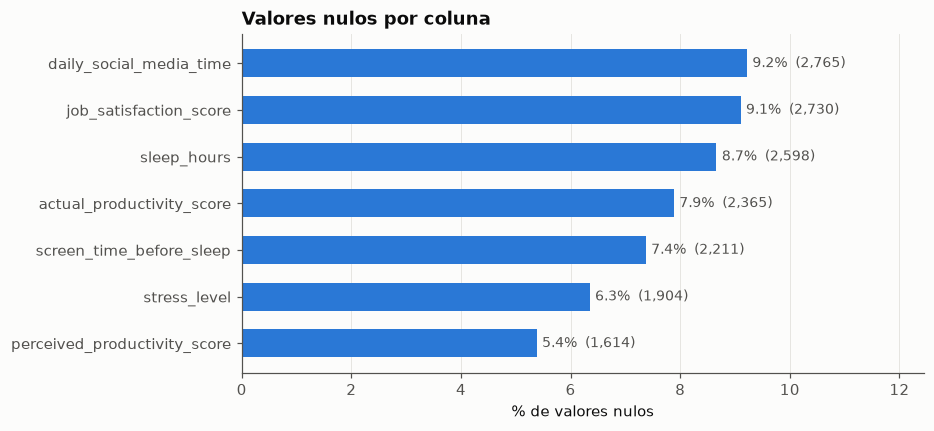

Linhas duplicadas: 0
Linhas completas (sem nenhum nulo): 17,074 (56.9%)

Quantidade de nulos por linha:
0    17074
1    10070
2     2475
3      358
4       22
5        1


In [5]:
nulos = df_raw.isna().sum()
nulos = nulos[nulos > 0].sort_values()
pct = (nulos / len(df_raw) * 100)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(pct.index, pct.values, color=BLUE, height=0.6)
for i, (n, p) in enumerate(zip(nulos.values, pct.values)):
    ax.text(p + 0.1, i, f"{p:.1f}%  ({n:,})", va="center", fontsize=9, color=INK_2)
ax.set_xlabel("% de valores nulos")
ax.set_title("Valores nulos por coluna")
ax.set_xlim(0, pct.max() * 1.35)
ax.grid(axis="y", visible=False)
salvar(fig, "01_nulos_por_coluna")
plt.show()

print(f"Linhas duplicadas: {df_raw.duplicated().sum()}")
print(f"Linhas completas (sem nenhum nulo): {df_raw.notna().all(axis=1).sum():,} "
      f"({df_raw.notna().all(axis=1).mean():.1%})")
print("\nQuantidade de nulos por linha:")
print(df_raw.isna().sum(axis=1).value_counts().sort_index().to_string())

In [6]:
# Os nulos são aleatórios (MCAR) ou seguem algum padrão?
# Comparamos a produtividade real de quem tem e de quem não tem cada campo preenchido.
cols_nulas = [c for c in nulos.index if c != "actual_productivity_score"]
teste_mcar = pd.DataFrame({
    "media_alvo_quando_nulo": [df_raw.loc[df_raw[c].isna(), "actual_productivity_score"].mean() for c in cols_nulas],
    "media_alvo_quando_preenchido": [df_raw.loc[df_raw[c].notna(), "actual_productivity_score"].mean() for c in cols_nulas],
}, index=cols_nulas)
teste_mcar["diferenca"] = teste_mcar.iloc[:, 0] - teste_mcar.iloc[:, 1]
teste_mcar

,media_alvo_quando_nulo,media_alvo_quando_preenchido,diferenca
perceived_productivity_score,4.98,4.95,0.03
stress_level,4.90,4.96,-0.06
screen_time_before_sleep,4.90,4.96,-0.06
sleep_hours,5.00,4.95,0.05
job_satisfaction_score,4.95,4.95,0.00
daily_social_media_time,4.99,4.95,0.04


**Leitura:** 7 colunas têm entre 5% e 9% de nulos, 43% das linhas têm pelo menos um campo vazio e não há duplicatas. A produtividade média praticamente não muda entre registros com e sem o campo preenchido (diferenças na casa dos centésimos), o que indica que os nulos são **aleatórios (MCAR)**. Isso permite uma imputação simples sem introduzir viés relevante.

## 4. Distribuições univariadas

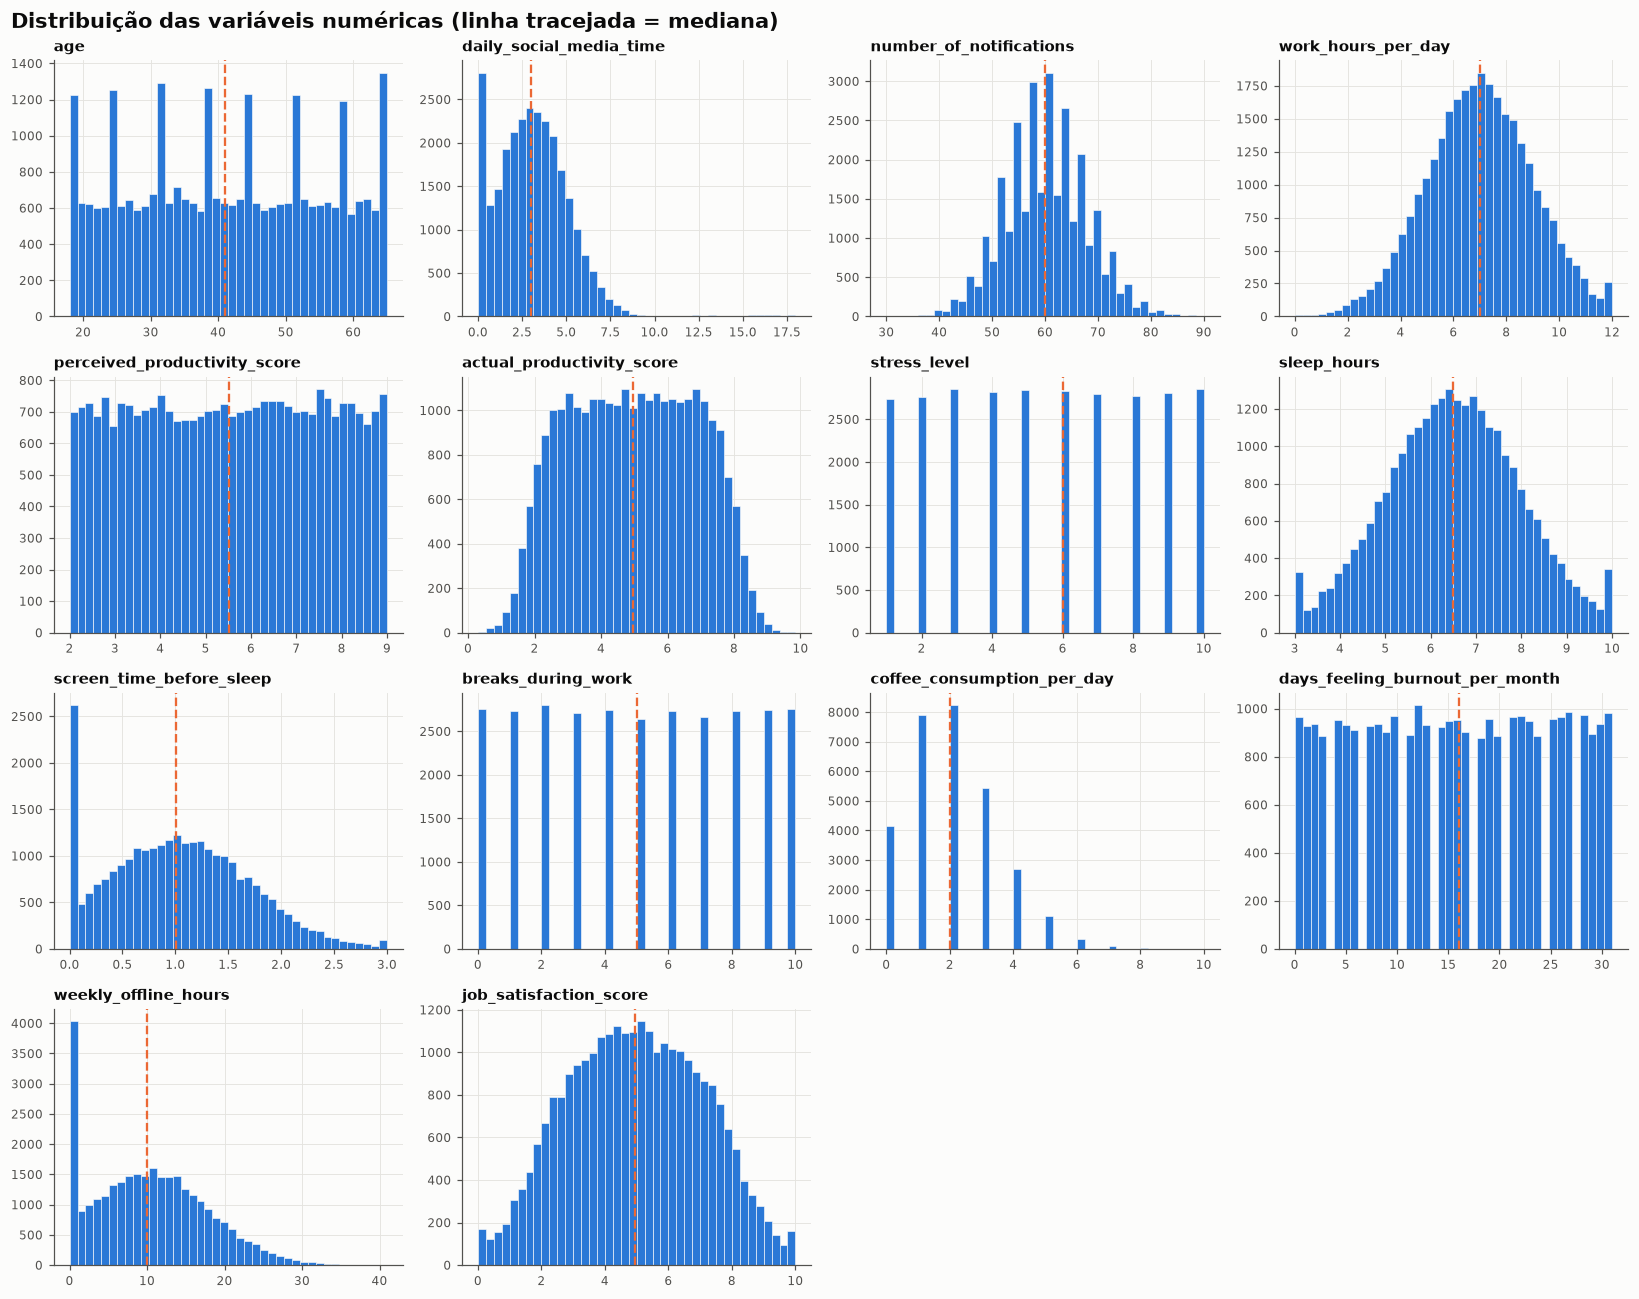

Assimetria (skewness):
daily_social_media_time           1.19
coffee_consumption_per_day        0.67
weekly_offline_hours              0.42
screen_time_before_sleep          0.30
number_of_notifications           0.12
age                               0.02
job_satisfaction_score            0.01
breaks_during_work                0.01
sleep_hours                       0.00
stress_level                      0.00
actual_productivity_score        -0.01
days_feeling_burnout_per_month   -0.01
perceived_productivity_score     -0.01
work_hours_per_day               -0.04


In [7]:
num_cols = df_raw.select_dtypes("number").columns.tolist()

fig, axes = plt.subplots(4, 4, figsize=(15, 12))
for ax, col in zip(axes.flat, num_cols):
    dados = df_raw[col].dropna()
    ax.hist(dados, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.4)
    ax.axvline(dados.median(), color=ORANGE, lw=1.5, ls="--")
    ax.set_title(col, fontsize=10)
    ax.tick_params(labelsize=8)
for ax in axes.flat[len(num_cols):]:
    ax.remove()
fig.suptitle("Distribuição das variáveis numéricas (linha tracejada = mediana)", x=0.01, ha="left",
             fontsize=14, fontweight="bold")
fig.tight_layout()
salvar(fig, "01_distribuicoes_numericas")
plt.show()

print("Assimetria (skewness):")
print(df_raw[num_cols].skew().sort_values(ascending=False).round(2).to_string())

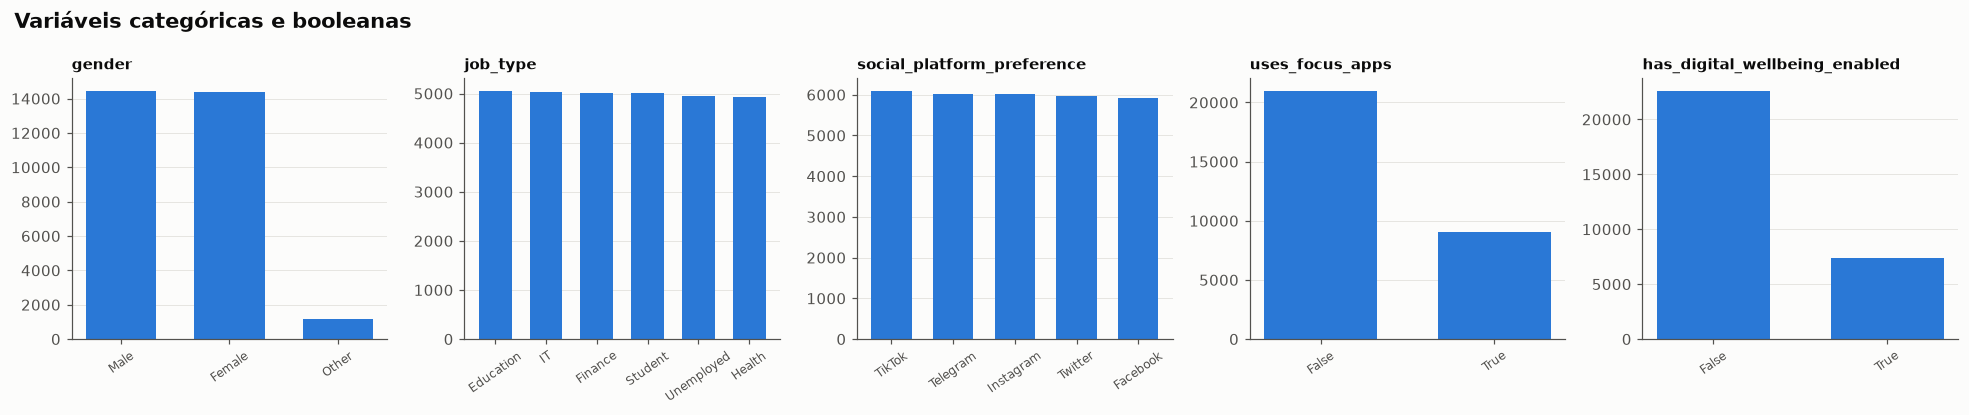

In [8]:
cat_cols = ["gender", "job_type", "social_platform_preference", "uses_focus_apps", "has_digital_wellbeing_enabled"]

fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))
for ax, col in zip(axes, cat_cols):
    vc = df_raw[col].value_counts()
    ax.bar(vc.index.astype(str), vc.values, color=BLUE, width=0.65)
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis="x", rotation=35, labelsize=8)
    ax.grid(axis="x", visible=False)
fig.suptitle("Variáveis categóricas e booleanas", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
salvar(fig, "01_distribuicoes_categoricas")
plt.show()

**Leitura:**

- A maioria das variáveis tem distribuição aproximadamente **uniforme ou normal** e bem comportada.
- `daily_social_media_time` é **assimétrica à direita**: a maior parte das pessoas usa de 1 a 5 h/dia, mas existe uma cauda de usuários intensos que chega a quase 18 h. `weekly_offline_hours` concentra muitos zeros. Por causa dessas caudas, a **mediana** é um imputador mais robusto que a média.
- As categorias de `job_type` e de `social_platform_preference` estão **balanceadas** (~5.000 e ~6.000 pessoas cada). `gender` tem a categoria *Other* minoritária (~4%).
- Só **30%** usam apps de foco e **25%** têm bem-estar digital ativado.

## 5. A variável de produtividade: percebida vs real

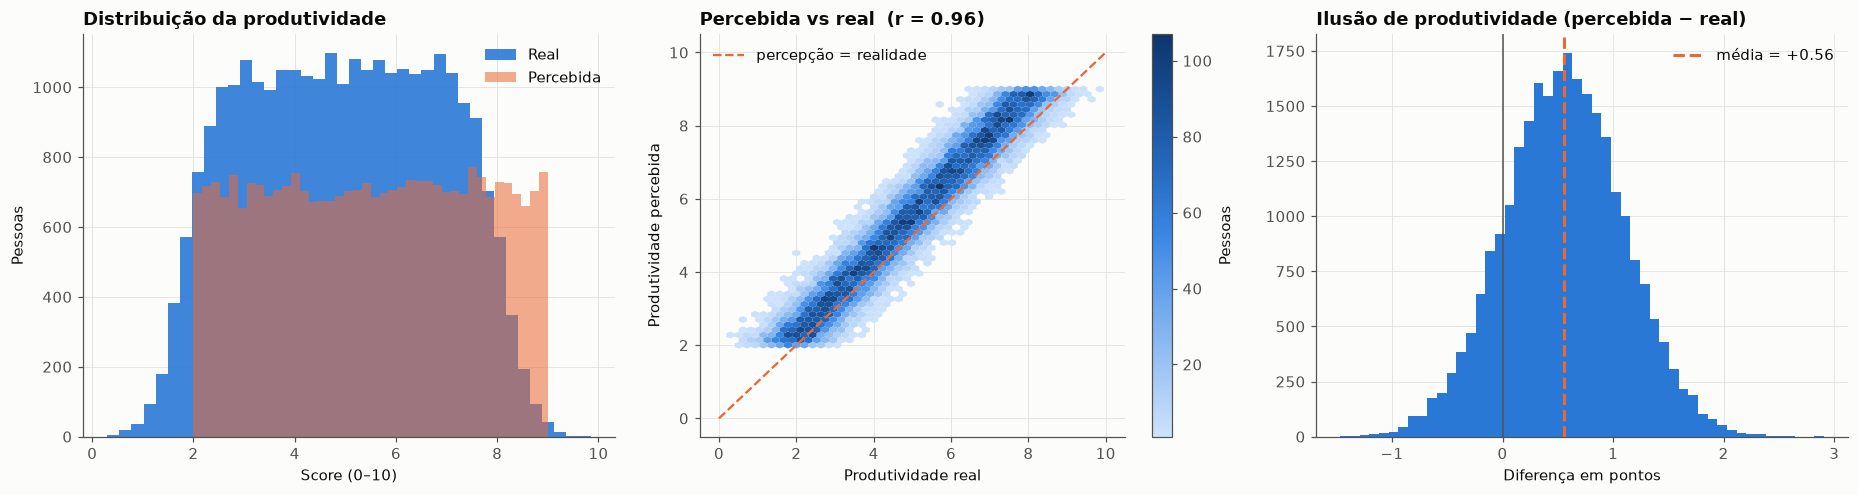

Pessoas que se acham MAIS produtivas do que são: 84.7%
Superestimação média: +0.56 pontos


In [9]:
prod = df_raw[["perceived_productivity_score", "actual_productivity_score"]].dropna()
gap = prod["perceived_productivity_score"] - prod["actual_productivity_score"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

ax = axes[0]
ax.hist(df_raw["actual_productivity_score"].dropna(), bins=40, color=BLUE, alpha=0.9, label="Real")
ax.hist(df_raw["perceived_productivity_score"].dropna(), bins=40, color=ORANGE, alpha=0.55, label="Percebida")
ax.set_title("Distribuição da produtividade")
ax.set_xlabel("Score (0–10)")
ax.set_ylabel("Pessoas")
ax.legend()

ax = axes[1]
hb = ax.hexbin(prod["actual_productivity_score"], prod["perceived_productivity_score"],
               gridsize=45, cmap=SEQ, mincnt=1, linewidths=0)
ax.plot([0, 10], [0, 10], color=ORANGE, lw=1.5, ls="--", label="percepção = realidade")
ax.set_xlabel("Produtividade real")
ax.set_ylabel("Produtividade percebida")
ax.set_title(f"Percebida vs real  (r = {prod.corr().iloc[0, 1]:.2f})")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="Pessoas")

ax = axes[2]
ax.hist(gap, bins=50, color=BLUE)
ax.axvline(0, color=INK_2, lw=1)
ax.axvline(gap.mean(), color=ORANGE, lw=2, ls="--", label=f"média = {gap.mean():+.2f}")
ax.set_title("Ilusão de produtividade (percebida − real)")
ax.set_xlabel("Diferença em pontos")
ax.legend()

fig.tight_layout()
salvar(fig, "01_produtividade_percebida_vs_real")
plt.show()

print(f"Pessoas que se acham MAIS produtivas do que são: {(gap > 0).mean():.1%}")
print(f"Superestimação média: {gap.mean():+.2f} pontos")

In [10]:
# A superestimação depende do nível real de produtividade?
faixas = pd.cut(prod["actual_productivity_score"], bins=[0, 2, 4, 6, 8, 10])
gap.groupby(faixas, observed=True).agg(["mean", "count"]).rename(
    columns={"mean": "superestimacao_media", "count": "pessoas"})

,superestimacao_media,pessoas
actual_productivity_score,,
"(0, 2]",0.76,1289
"(2, 4]",0.38,7789
"(4, 6]",0.57,8352
"(6, 8]",0.71,7677
"(8, 10]",0.30,1043


**Leitura (comportamento humano):** as duas medidas andam juntas (r ≈ 0,96), mas **cerca de 85% das pessoas se avaliam como mais produtivas do que realmente são**, em média +0,56 ponto. A superestimação aparece em **todas** as faixas de produtividade real. Os extremos devem ser lidos com cuidado: o histograma mostra que a nota percebida fica **limitada ao intervalo 2–9**. Esse piso em 2 infla a diferença de quem tem produtividade real muito baixa, e o teto em 9 reduz a diferença de quem é muito produtivo. Nas faixas centrais, sem esse efeito de borda, o viés é consistente e fica entre +0,4 e +0,7.

Essa correlação quase perfeita é um alerta importante para a modelagem (ver Seção 8).

## 6. Correlações

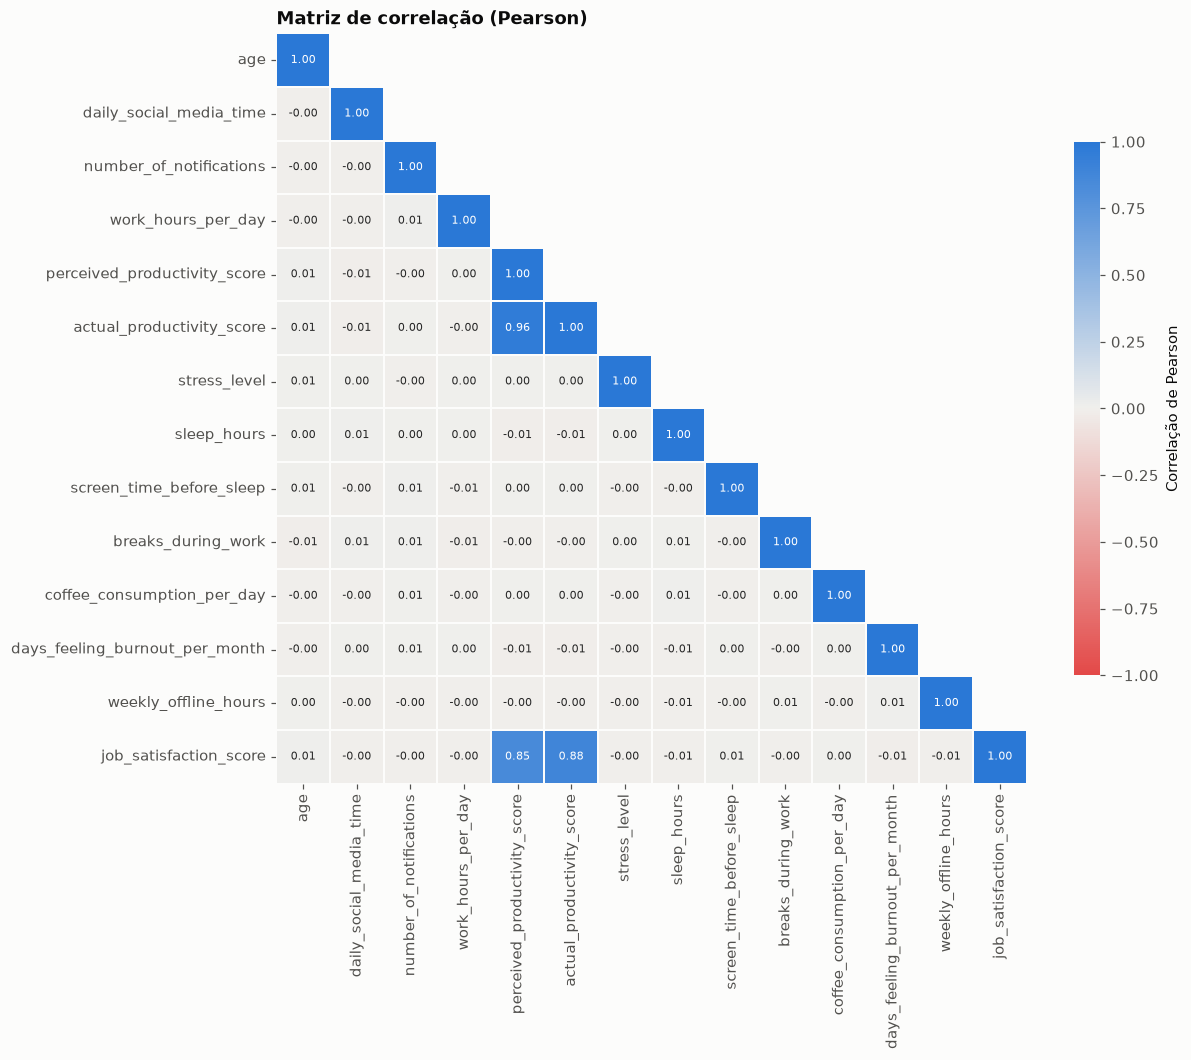

In [11]:
corr = df_raw[num_cols].corr(method="pearson")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, cmap=DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=1, linecolor=SURFACE, square=True,
            cbar_kws={"shrink": 0.7, "label": "Correlação de Pearson"}, ax=ax)
ax.set_title("Matriz de correlação (Pearson)")
ax.grid(False)
salvar(fig, "01_matriz_correlacao")
plt.show()

In [12]:
# Correlação linear e de Spearman (monotônica) de cada variável com o alvo
alvo = "actual_productivity_score"
corr_alvo = pd.DataFrame({
    "pearson": df_raw[num_cols].corr(method="pearson")[alvo],
    "spearman": df_raw[num_cols].corr(method="spearman")[alvo],
}).drop(alvo).sort_values("pearson", key=abs, ascending=False)
corr_alvo

,pearson,spearman
perceived_productivity_score,0.96,0.97
job_satisfaction_score,0.88,0.89
days_feeling_burnout_per_month,-0.01,-0.01
daily_social_media_time,-0.01,-0.01
age,0.01,0.01
sleep_hours,-0.01,-0.01
weekly_offline_hours,-0.00,-0.01
breaks_during_work,-0.00,-0.00
screen_time_before_sleep,0.00,0.00
stress_level,0.00,0.00


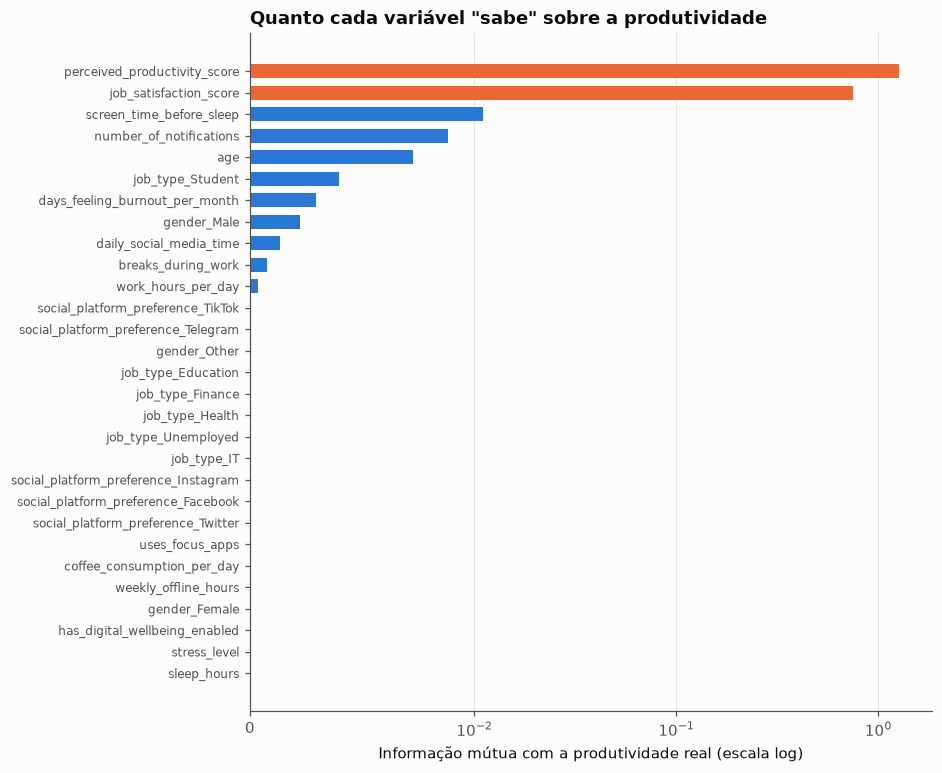

perceived_productivity_score     1.27
job_satisfaction_score           0.75
screen_time_before_sleep         0.01
number_of_notifications          0.01
age                              0.01
job_type_Student                 0.00
days_feeling_burnout_per_month   0.00
gender_Male                      0.00
dtype: float64

In [13]:
# Informação mútua: capta também relações NÃO lineares (que um Random Forest conseguiria explorar)
base_mi = df_raw.dropna().copy()
X_mi = pd.get_dummies(base_mi.drop(columns=[alvo]), dtype=float)
mi = pd.Series(mutual_info_regression(X_mi, base_mi[alvo], random_state=RANDOM_STATE),
               index=X_mi.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
cores = [ORANGE if v > 0.1 else BLUE for v in mi.values]
ax.barh(mi.index, mi.values, color=cores, height=0.65)
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlabel("Informação mútua com a produtividade real (escala log)")
ax.set_title("Quanto cada variável \"sabe\" sobre a produtividade")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
salvar(fig, "01_informacao_mutua")
plt.show()
mi.sort_values(ascending=False).head(8)

**Leitura (achado central da EDA):**

- Só **duas** variáveis têm relação forte com a produtividade real: `perceived_productivity_score` (r ≈ 0,96) e `job_satisfaction_score` (r ≈ 0,88).
- **Todos os hábitos digitais** (tempo em redes sociais, notificações, tela antes de dormir, horas offline) e as variáveis de bem-estar (sono, estresse, burnout) têm correlação **praticamente nula** com o alvo, |r| < 0,02.
- A informação mútua, que capta relações não lineares, confirma o quadro: fora as duas variáveis citadas, nenhuma passa de ~0,01.
- As variáveis explicativas também são **quase independentes entre si** (por exemplo, mais tempo em redes sociais não está associado a menos sono nem a mais estresse). Isso sugere um dataset **sintético**, em que os atributos foram gerados de forma independente.

Este é um resultado legítimo e importante para o projeto: **neste dataset, o tempo em redes sociais não prevê a produtividade**. Nas seções seguintes verificamos esse resultado por cruzamentos visuais, para garantir que não há padrões escondidos em subgrupos.

## 7. Cruzamentos comportamentais

### 7.1 Tempo em redes sociais vs produtividade

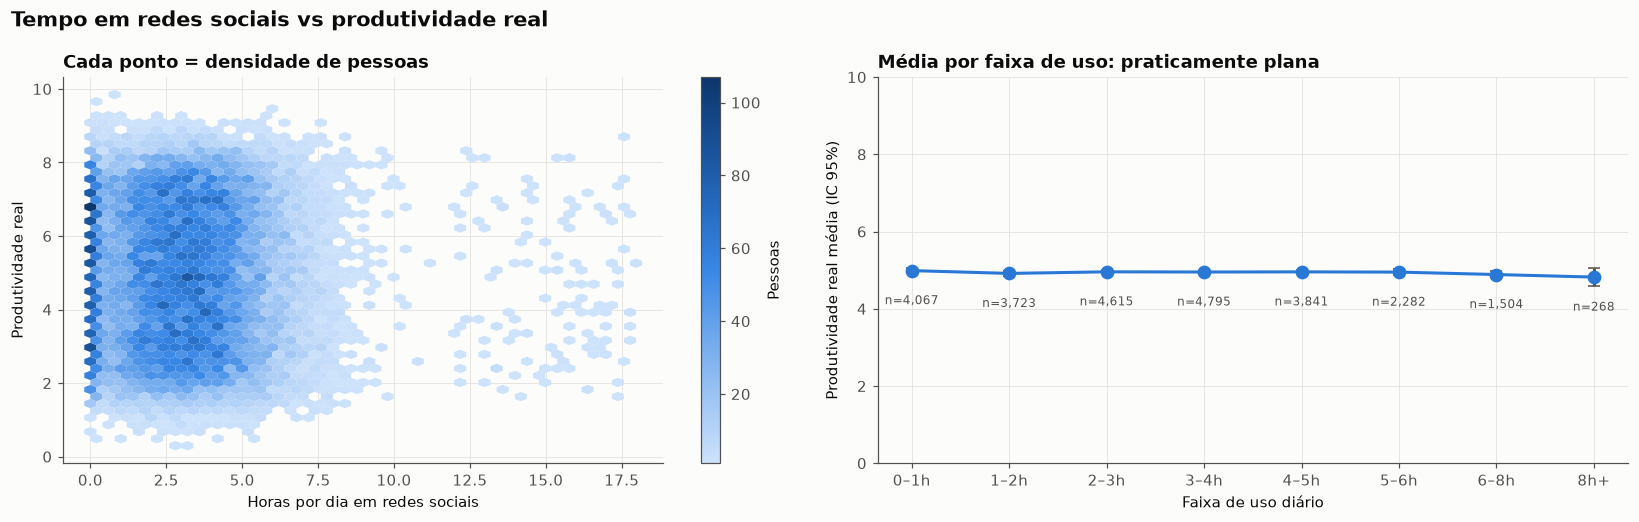

,mean,sem,count
faixa,,,
0–1h,4.99,0.03,4067
1–2h,4.92,0.03,3723
2–3h,4.96,0.03,4615
3–4h,4.95,0.03,4795
4–5h,4.96,0.03,3841
5–6h,4.95,0.04,2282
6–8h,4.89,0.05,1504
8h+,4.82,0.12,268


In [14]:
sm = df_raw[["daily_social_media_time", alvo]].dropna()
sm["faixa"] = pd.cut(sm["daily_social_media_time"], bins=[0, 1, 2, 3, 4, 5, 6, 8, 20],
                     labels=["0–1h", "1–2h", "2–3h", "3–4h", "4–5h", "5–6h", "6–8h", "8h+"], include_lowest=True)
resumo = sm.groupby("faixa", observed=True)[alvo].agg(["mean", "sem", "count"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

ax = axes[0]
hb = ax.hexbin(sm["daily_social_media_time"], sm[alvo], gridsize=45, cmap=SEQ, mincnt=1, linewidths=0)
ax.set_xlabel("Horas por dia em redes sociais")
ax.set_ylabel("Produtividade real")
ax.set_title("Cada ponto = densidade de pessoas")
fig.colorbar(hb, ax=ax, label="Pessoas")

ax = axes[1]
x = np.arange(len(resumo))
ax.errorbar(x, resumo["mean"], yerr=1.96 * resumo["sem"], fmt="o-", color=BLUE, lw=2, ms=8,
            capsize=4, ecolor=INK_2)
ax.set_xticks(x, resumo.index)
ax.set_ylim(0, 10)
ax.set_xlabel("Faixa de uso diário")
ax.set_ylabel("Produtividade real média (IC 95%)")
ax.set_title("Média por faixa de uso: praticamente plana")
for xi, (m, n) in enumerate(zip(resumo["mean"], resumo["count"])):
    ax.annotate(f"n={n:,}", (xi, m), xytext=(0, -22), textcoords="offset points", ha="center",
                fontsize=8, color=INK_2)

fig.suptitle("Tempo em redes sociais vs produtividade real", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
salvar(fig, "01_redes_sociais_vs_produtividade")
plt.show()
resumo

### 7.2 Rede social favorita

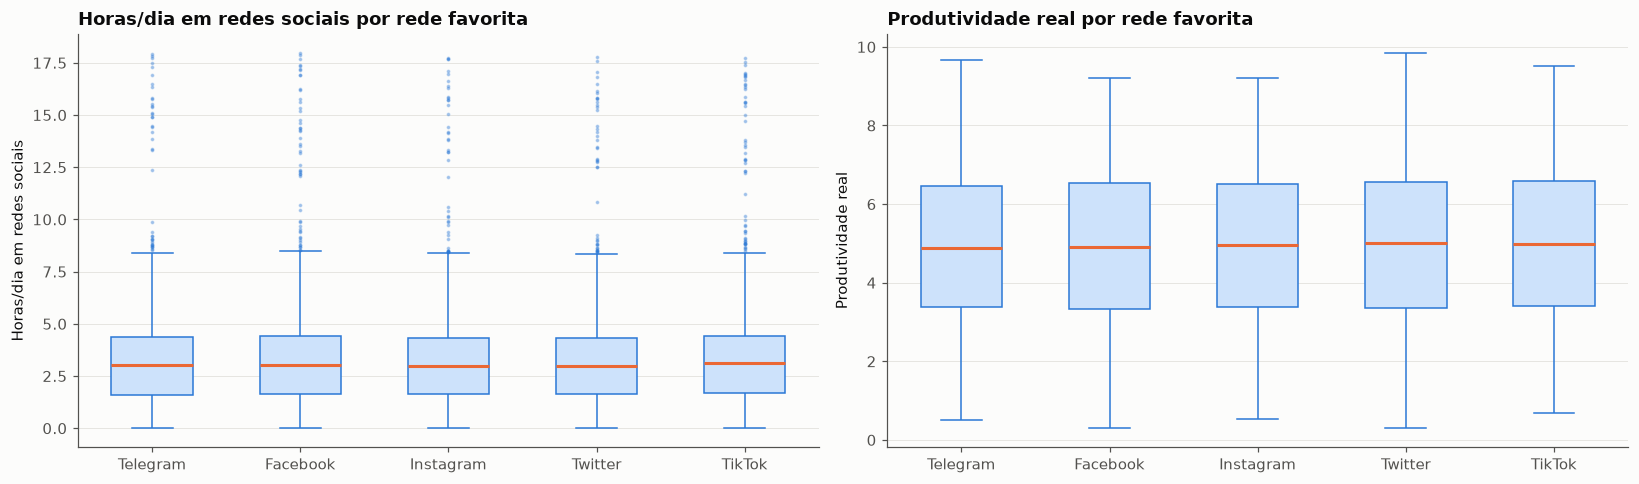

,produtividade,uso_diario,notificacoes,tela_antes_dormir,pessoas
social_platform_preference,,,,,
Telegram,4.92,3.08,59.97,1.03,6013
Facebook,4.93,3.14,60.05,1.02,5921
Instagram,4.95,3.10,59.99,1.02,6006
Twitter,4.97,3.08,59.93,1.04,5964
TikTok,4.98,3.17,59.87,1.03,6096


In [15]:
plataformas = df_raw.groupby("social_platform_preference").agg(
    produtividade=(alvo, "mean"),
    uso_diario=("daily_social_media_time", "mean"),
    notificacoes=("number_of_notifications", "mean"),
    tela_antes_dormir=("screen_time_before_sleep", "mean"),
    pessoas=(alvo, "size"),
).sort_values("produtividade")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (col, rotulo) in zip(axes, [("daily_social_media_time", "Horas/dia em redes sociais"),
                                    (alvo, "Produtividade real")]):
    sns.boxplot(data=df_raw, x="social_platform_preference", y=col, order=plataformas.index,
                color=BLUE, width=0.55, fliersize=1.5, linewidth=1,
                boxprops={"facecolor": "#cde2fb", "edgecolor": BLUE},
                medianprops={"color": ORANGE, "linewidth": 2},
                whiskerprops={"color": BLUE}, capprops={"color": BLUE},
                flierprops={"markerfacecolor": BLUE, "markeredgecolor": BLUE, "alpha": 0.3}, ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel(rotulo)
    ax.set_title(rotulo + " por rede favorita")
fig.tight_layout()
salvar(fig, "01_plataformas")
plt.show()
plataformas

### 7.3 Ferramentas de foco e bem-estar digital

In [16]:
ferramentas = (df_raw
    .assign(apps_foco=df_raw["uses_focus_apps"].map({True: "Usa apps de foco", False: "Não usa"}),
            bem_estar=df_raw["has_digital_wellbeing_enabled"].map({True: "Bem-estar digital ON", False: "OFF"}))
    .pivot_table(index="apps_foco", columns="bem_estar", values=alvo, aggfunc=["mean", "size"]))
ferramentas

mean                      size       
bem_estar        Bem-estar digital ON  OFF Bem-estar digital ON    OFF
apps_foco                                                             
Não usa                          4.94 4.96                 5154  15825
Usa apps de foco                 4.90 4.96                 2244   6777

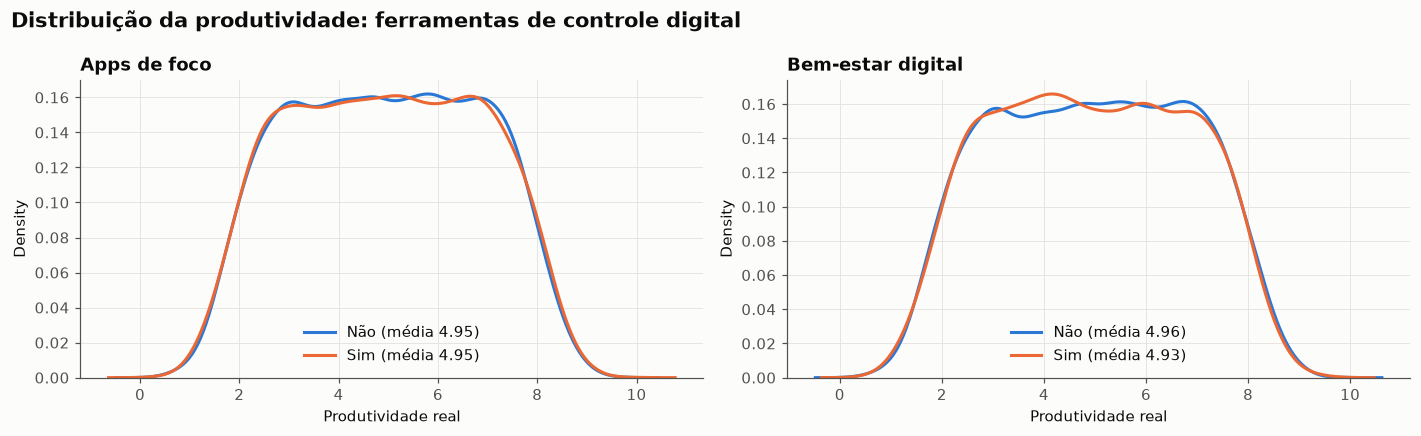

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, rotulo in [(axes[0], "uses_focus_apps", "Apps de foco"),
                        (axes[1], "has_digital_wellbeing_enabled", "Bem-estar digital")]:
    for valor, cor, nome in [(False, BLUE, "Não"), (True, ORANGE, "Sim")]:
        sns.kdeplot(df_raw.loc[df_raw[col] == valor, alvo].dropna(), ax=ax, color=cor, lw=2,
                    label=f"{nome} (média {df_raw.loc[df_raw[col] == valor, alvo].mean():.2f})")
    ax.set_title(rotulo)
    ax.set_xlabel("Produtividade real")
    ax.legend()
fig.suptitle("Distribuição da produtividade: ferramentas de controle digital", x=0.01, ha="left",
             fontsize=14, fontweight="bold")
fig.tight_layout()
salvar(fig, "01_ferramentas_foco")
plt.show()

### 7.4 Área de atuação

In [18]:
por_trabalho = df_raw.groupby("job_type").agg(
    produtividade=(alvo, "mean"),
    satisfacao=("job_satisfaction_score", "mean"),
    redes_sociais=("daily_social_media_time", "mean"),
    horas_trabalho=("work_hours_per_day", "mean"),
    estresse=("stress_level", "mean"),
    burnout=("days_feeling_burnout_per_month", "mean"),
).sort_values("produtividade", ascending=False)
por_trabalho

,produtividade,satisfacao,redes_sociais,horas_trabalho,estresse,burnout
job_type,,,,,,
IT,5.01,5.04,3.13,6.98,5.54,15.66
Unemployed,4.99,4.95,3.16,7.04,5.47,15.58
Finance,4.97,4.95,3.08,6.99,5.59,15.67
Education,4.93,4.95,3.10,6.95,5.51,15.41
Health,4.92,4.97,3.07,7.01,5.50,15.54
Student,4.90,4.93,3.14,6.98,5.47,15.48


### 7.5 Sono, tela antes de dormir e estresse

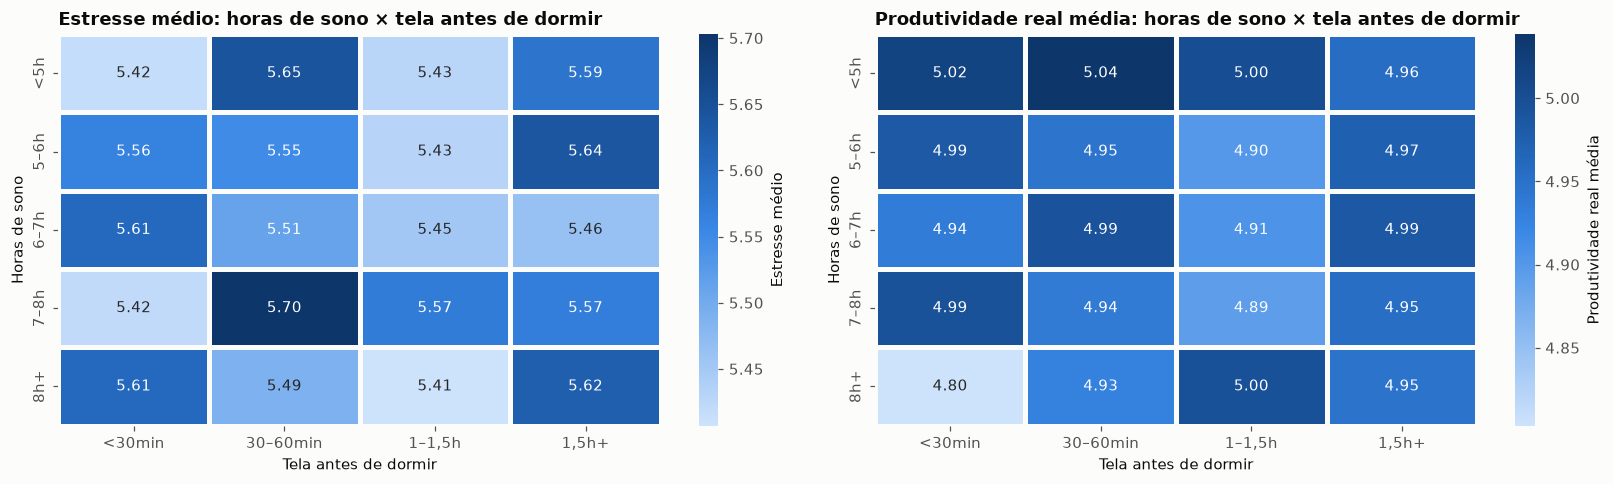

In [19]:
sono = df_raw[["sleep_hours", "screen_time_before_sleep", "stress_level", alvo]].dropna().copy()
sono["sono"] = pd.cut(sono["sleep_hours"], bins=[0, 5, 6, 7, 8, 11], labels=["<5h", "5–6h", "6–7h", "7–8h", "8h+"])
sono["tela"] = pd.cut(sono["screen_time_before_sleep"], bins=[-0.01, 0.5, 1, 1.5, 3.1],
                      labels=["<30min", "30–60min", "1–1,5h", "1,5h+"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, valor, titulo in [(axes[0], "stress_level", "Estresse médio"),
                          (axes[1], alvo, "Produtividade real média")]:
    tabela = sono.pivot_table(index="sono", columns="tela", values=valor, aggfunc="mean", observed=True)
    sns.heatmap(tabela, annot=True, fmt=".2f", cmap=SEQ, linewidths=2, linecolor=SURFACE,
                cbar_kws={"label": titulo}, ax=ax)
    ax.set_title(f"{titulo}: horas de sono × tela antes de dormir")
    ax.set_xlabel("Tela antes de dormir")
    ax.set_ylabel("Horas de sono")
    ax.grid(False)
fig.tight_layout()
salvar(fig, "01_sono_tela_estresse")
plt.show()

### 7.6 Satisfação com o trabalho: o fator dominante

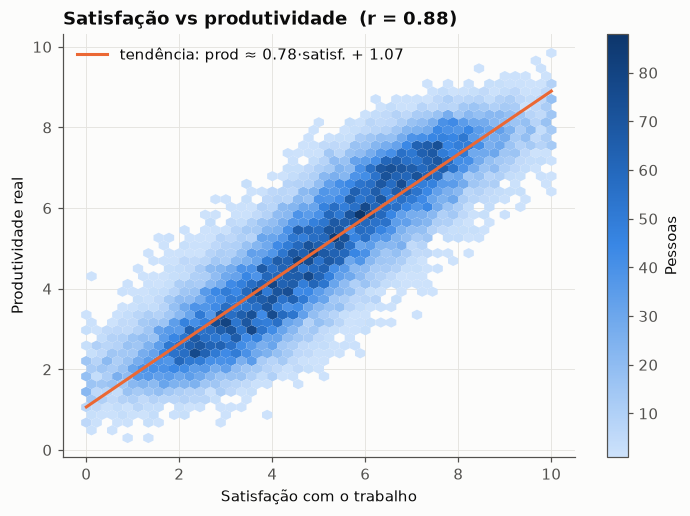

In [20]:
sat = df_raw[["job_satisfaction_score", alvo]].dropna()

fig, ax = plt.subplots(figsize=(7.5, 5))
hb = ax.hexbin(sat["job_satisfaction_score"], sat[alvo], gridsize=45, cmap=SEQ, mincnt=1, linewidths=0)
coef = np.polyfit(sat["job_satisfaction_score"], sat[alvo], 1)
xs = np.linspace(0, 10, 50)
ax.plot(xs, np.polyval(coef, xs), color=ORANGE, lw=2,
        label=f"tendência: prod ≈ {coef[0]:.2f}·satisf. + {coef[1]:.2f}")
ax.set_xlabel("Satisfação com o trabalho")
ax.set_ylabel("Produtividade real")
ax.set_title(f"Satisfação vs produtividade  (r = {sat.corr().iloc[0, 1]:.2f})")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="Pessoas")
salvar(fig, "01_satisfacao_vs_produtividade")
plt.show()

### 7.7 Curvas de dose-resposta: todos os hábitos de uma vez

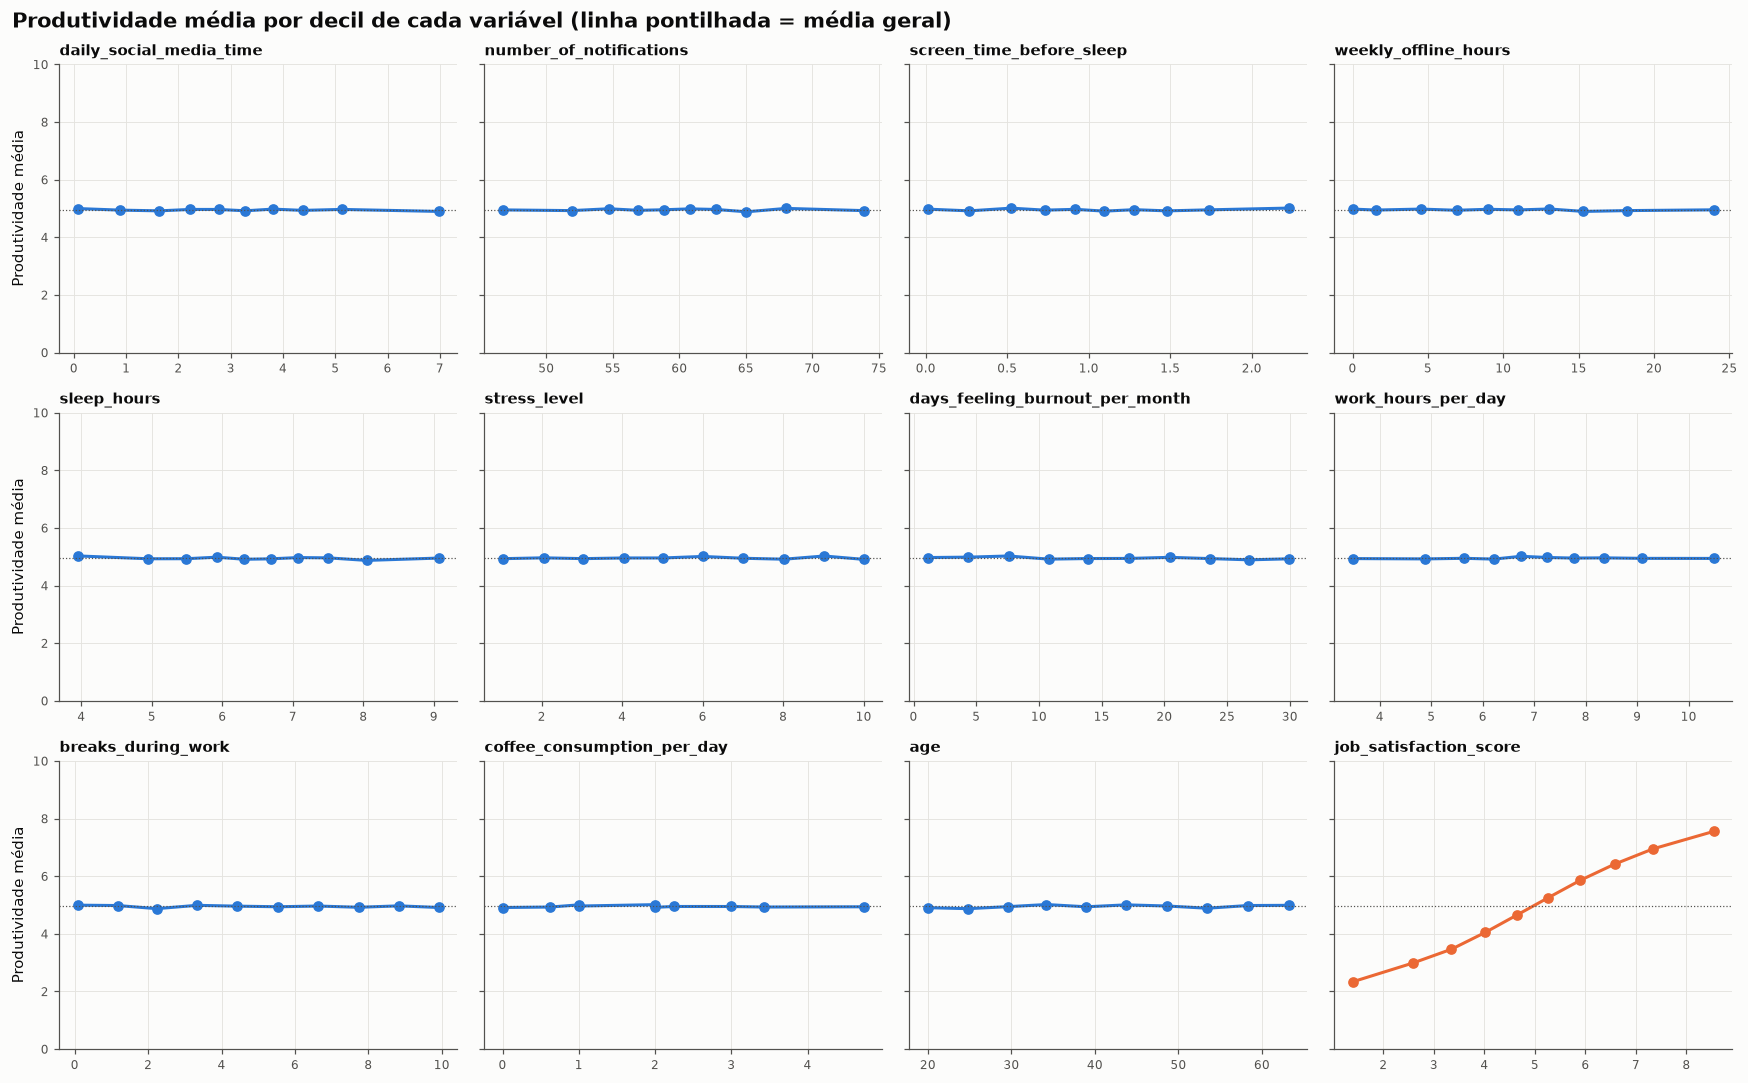

In [21]:
# Para cada variável: produtividade média em cada decil da variável.
# Uma linha plana = aumentar o hábito não muda a produtividade.
habitos = ["daily_social_media_time", "number_of_notifications", "screen_time_before_sleep",
           "weekly_offline_hours", "sleep_hours", "stress_level", "days_feeling_burnout_per_month",
           "work_hours_per_day", "breaks_during_work", "coffee_consumption_per_day", "age",
           "job_satisfaction_score"]

fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharey=True)
for ax, col in zip(axes.flat, habitos):
    d = df_raw[[col, alvo]].dropna()
    decil = pd.qcut(d[col].rank(method="first"), 10, labels=False)
    g = d.groupby(decil).agg(x=(col, "mean"), y=(alvo, "mean"))
    cor = ORANGE if col == "job_satisfaction_score" else BLUE
    ax.plot(g["x"], g["y"], "o-", color=cor, lw=2, ms=6)
    ax.axhline(d[alvo].mean(), color=INK_2, lw=0.8, ls=":")
    ax.set_title(col, fontsize=10)
    ax.set_ylim(0, 10)
    ax.tick_params(labelsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("Produtividade média")
fig.suptitle("Produtividade média por decil de cada variável (linha pontilhada = média geral)",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
salvar(fig, "01_dose_resposta")
plt.show()

**Leitura dos cruzamentos:**

- **Tempo em redes sociais:** a produtividade média fica entre **4,9 e 5,0** de 0 a 6 h/dia. Nas faixas extremas há uma leve queda (4,89 em 6–8 h e 4,82 em 8 h+), de menos de 0,2 ponto numa escala de 0 a 10. Essa queda vem de poucas pessoas (268 no grupo 8 h+) e o intervalo de confiança se sobrepõe ao das demais faixas, então é um efeito **muito pequeno e estatisticamente frágil**.
- **Rede favorita:** usuários de TikTok, Instagram, Facebook, Twitter e Telegram têm o mesmo tempo de uso e a mesma produtividade; as diferenças ficam na casa dos centésimos.
- **Apps de foco e bem-estar digital:** as distribuições de produtividade de quem usa e de quem não usa são praticamente idênticas. **Ter a ferramenta não equivale a ser mais produtivo.**
- **Área de atuação:** nenhuma área se destaca em produtividade, estresse ou burnout.
- **Sono e tela:** dormir pouco ou usar tela antes de dormir não altera, neste dataset, nem o estresse médio nem a produtividade.
- **Satisfação com o trabalho:** é a única curva com inclinação clara. Cada ponto a mais de satisfação corresponde a ~0,8 ponto a mais de produtividade.

### Síntese da EDA

1. A produtividade real depende quase inteiramente da **satisfação com o trabalho** (e, por consequência, da autopercepção).
2. Os hábitos digitais **não têm sinal preditivo detectável**, nem linear nem não linear, nem em subgrupos.
3. As pessoas **superestimam** sistematicamente a própria produtividade.

Para a modelagem, a expectativa é que o Random Forest atribua quase toda a importância a `job_satisfaction_score`. Isso será verificado nas Fases 3 e 4, e é em si uma resposta para a pergunta do projeto: **"redes sociais derrubam a produtividade?" — nestes dados, não.**

## 8. Definição do alvo e do tipo de problema

### Alvo: `actual_productivity_score`

É a medida **objetiva** de produtividade, que é exatamente o que queremos prever a partir dos hábitos de uma pessoa.

### Regressão ou classificação? **Regressão.**

| Critério | Regressão | Classificação |
|---|---|---|
| Natureza do alvo | Contínuo, 0–10, com casas decimais | Exigiria criar faixas artificiais (baixa/média/alta) |
| Informação | Preserva toda a variação do score | Perde informação: 4,9 e 5,1 cairiam em classes diferentes, enquanto 3,4 e 4,9 ficariam juntos |
| Limiar | Nenhum limiar arbitrário | O corte entre classes seria uma escolha nossa, sem respaldo no domínio |
| Interface (Fase 6) | Mostra um score preciso, ex.: "6,8/10" | Mostraria só um rótulo |

Usaremos o **`RandomForestRegressor`**, avaliado por **RMSE, MAE e R²** na Fase 3.

### Remoção de `perceived_productivity_score` (data leakage)

A produtividade percebida é a **autoavaliação da mesma grandeza** que queremos prever, coletada ao mesmo tempo (r ≈ 0,96). Usá-la como entrada seria prever "a produtividade a partir da própria produtividade". O modelo teria métricas excelentes, mas não aprenderia nada sobre **hábitos**, e na interface o usuário precisaria informar quão produtivo se acha para descobrir quão produtivo é. Por isso a coluna é **removida** das features.

`job_satisfaction_score` é **mantida**: é uma característica do contexto de trabalho da pessoa, conhecida antes do resultado e que pode ser informada na interface.

## 9. Pré-processamento

In [22]:
df = df_raw.copy()

# 9.1 Linhas sem alvo não servem para treino nem teste supervisionado: imputar o alvo inventaria rótulos.
antes = len(df)
df = df.dropna(subset=[alvo])
print(f"Linhas removidas por alvo nulo: {antes - len(df):,}  ->  restam {len(df):,}")

# 9.2 Remove a variável com vazamento de informação do alvo.
df = df.drop(columns=["perceived_productivity_score"])

Linhas removidas por alvo nulo: 2,365  ->  restam 27,635


In [23]:
# 9.3 Imputação das features numéricas pela mediana.
# Justificativa: os nulos são MCAR (Seção 3) e algumas distribuições têm cauda longa (Seção 4).
# Observação: as medianas são calculadas no dataset inteiro, antes do split. Com ~27 mil linhas e nulos
# aleatórios, a diferença em relação a medianas só do treino é desprezível (ver comparação abaixo).
cols_imputar = [c for c in df.columns if df[c].isna().any()]
medianas = df[cols_imputar].median()

amostra_treino = df.sample(frac=0.8, random_state=RANDOM_STATE)
print("Mediana no dataset completo vs numa amostra de 80% (simulando o treino):")
print(pd.DataFrame({"completo": medianas, "amostra_80%": amostra_treino[cols_imputar].median()}).to_string())

df[cols_imputar] = df[cols_imputar].fillna(medianas)
print(f"\nNulos restantes: {df.isna().sum().sum()}")

Mediana no dataset completo vs numa amostra de 80% (simulando o treino):
                          completo  amostra_80%
daily_social_media_time       3.03         3.03
stress_level                  6.00         6.00
sleep_hours                   6.50         6.49
screen_time_before_sleep      1.01         1.01
job_satisfaction_score        4.94         4.94

Nulos restantes: 0


In [24]:
# 9.4 Booleanas -> 0/1
bool_cols = ["uses_focus_apps", "has_digital_wellbeing_enabled"]
df[bool_cols] = df[bool_cols].astype(int)

# 9.5 Categóricas nominais -> One-Hot Encoding.
# Não há ordem natural entre gêneros, áreas ou redes sociais; Label Encoding (0, 1, 2...) criaria
# uma ordem falsa. Mantemos todas as colunas dummy (sem drop_first): árvores não sofrem com
# multicolinearidade, e assim cada categoria aparece explicitamente na Feature Importance.
nominais = ["gender", "job_type", "social_platform_preference"]
df = pd.get_dummies(df, columns=nominais, prefix=["gender", "job", "platform"], dtype=int)

# Alvo como última coluna
df = df[[c for c in df.columns if c != alvo] + [alvo]]
print(f"Formato final: {df.shape[0]:,} linhas × {df.shape[1]} colunas ({df.shape[1] - 1} features + alvo)")
df.head()

Formato final: 27,635 linhas × 29 colunas (28 features + alvo)


,age,daily_social_media_time,number_of_notifications,work_hours_per_day,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,uses_focus_apps,has_digital_wellbeing_enabled,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,job_satisfaction_score,gender_Female,gender_Male,gender_Other,job_Education,job_Finance,job_Health,job_IT,job_Student,job_Unemployed,platform_Facebook,platform_Instagram,platform_Telegram,platform_TikTok,platform_Twitter,actual_productivity_score
0,56,4.18,61,6.75,4.00,5.12,0.42,8,0,0,4,11,21.93,6.34,0,1,0,0,0,0,0,0,1,1,0,0,0,0,7.29
1,46,3.25,59,9.17,7.00,5.10,0.67,7,1,1,2,25,0.00,3.41,0,1,0,0,0,1,0,0,0,0,0,0,0,1,5.17
2,32,3.03,57,7.91,4.00,8.58,0.62,0,1,0,3,17,10.32,2.47,0,1,0,0,1,0,0,0,0,0,0,0,0,1,3.47
3,60,3.03,59,6.36,6.00,6.05,1.20,1,0,0,0,4,23.88,1.73,1,0,0,0,0,0,0,0,1,1,0,0,0,0,1.77
5,38,1.51,50,6.43,5.00,5.52,1.52,5,0,1,5,2,0.00,4.57,0,1,0,0,1,0,0,0,0,0,0,0,0,1,4.08


In [25]:
# 9.6 Verificações finais
assert df.isna().sum().sum() == 0, "ainda há nulos"
assert all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes), "ainda há colunas não numéricas"
assert "perceived_productivity_score" not in df.columns

print("Tipos finais:")
print(df.dtypes.value_counts().to_string())
print("\nFeatures:")
print(", ".join(df.columns[:-1]))

Tipos finais:
int64      21
float64     8

Features:
age, daily_social_media_time, number_of_notifications, work_hours_per_day, stress_level, sleep_hours, screen_time_before_sleep, breaks_during_work, uses_focus_apps, has_digital_wellbeing_enabled, coffee_consumption_per_day, days_feeling_burnout_per_month, weekly_offline_hours, job_satisfaction_score, gender_Female, gender_Male, gender_Other, job_Education, job_Finance, job_Health, job_IT, job_Student, job_Unemployed, platform_Facebook, platform_Instagram, platform_Telegram, platform_TikTok, platform_Twitter


In [26]:
df.to_csv(DATA_DIR / "processed.csv", index=False)
print(f"Salvo em {DATA_DIR / 'processed.csv'}  ({(DATA_DIR / 'processed.csv').stat().st_size / 1e6:.1f} MB)")
print(f"Figuras salvas em {FIG_DIR}/: {sorted(p.name for p in FIG_DIR.glob('01_*.png'))}")

Salvo em data/processed.csv  (4.8 MB)
Figuras salvas em figures/: ['01_distribuicoes_categoricas.png', '01_distribuicoes_numericas.png', '01_dose_resposta.png', '01_ferramentas_foco.png', '01_informacao_mutua.png', '01_matriz_correlacao.png', '01_nulos_por_coluna.png', '01_plataformas.png', '01_produtividade_percebida_vs_real.png', '01_redes_sociais_vs_produtividade.png', '01_satisfacao_vs_produtividade.png', '01_sono_tela_estresse.png']


## 10. Resumo e próximos passos

| Etapa | Decisão |
|---|---|
| Alvo | `actual_productivity_score`, **regressão** |
| Nulos no alvo | 2.365 linhas removidas |
| Nulos nas features | Imputação pela **mediana** (nulos MCAR, distribuições assimétricas) |
| Leakage | `perceived_productivity_score` removida |
| Booleanas | Convertidas para 0/1 |
| Categóricas | One-Hot Encoding (gender, job_type, social_platform_preference) |
| Saída | `data/processed.csv` com 27.635 linhas e 29 colunas (28 features + alvo) |

**Fase 2:** dividir `data/processed.csv` em treino e teste e treinar o `RandomForestRegressor`.